In [1]:
import numpy as np
import skimage.io
import skimage.color
import skimage.filters
import skimage.transform
from skimage import img_as_ubyte
import matplotlib.pyplot as plt
import constants
import IPython.display as d
import json
import os
import time
import torch
from torchvision import transforms, utils, datasets
from torch.utils.data import Dataset, DataLoader
from torch.autograd import Variable
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import shutil
from sklearn import metrics
from PIL import Image
import json
import random
import pandas as pd
import tensorflow as tf
from keras import layers
from keras import initializers
import keras
import keras_tuner
import gc
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt

hp = keras_tuner.HyperParameters()

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
def test_model(model, dataset):
    filtered_data = []
    TP = 0
    FP = 0
    TN = 0
    FN = 0
    for i, (images, label) in enumerate(dataset, 0):
        output = model(images)
        prediction = output.numpy()
        for i in range(len(prediction)):
            if prediction[i][0] > 0.4:
                if label[i]== 1:
                    TP += 1
                else: FP += 1
                filtered_data.append(images[i])
                # print(prediction[i], label[i])
            else:
                if label[i]== 1:
                    FN += 1
                else: TN += 1

    f1 = (2*TP)/(2*TP+FP+FN)
    return filtered_data, TP, FP, TN, FN, f1

In [3]:
train_ds, valid_ds = tf.keras.utils.image_dataset_from_directory(
    directory='./data/images_128_train/',
    labels='inferred',
    label_mode='binary',
    batch_size=16,
    image_size=(128,128),
    validation_split=0.2,
    subset='both',
    seed=42
)
test_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_128_test/',
    labels='inferred',
    label_mode='binary',
    batch_size=16,
    image_size=(128,128),
    seed=42
)

def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label
train_ds = train_ds.map(process)
valid_ds = valid_ds.map(process)
test_ds = test_ds.map(process)

Found 4393 files belonging to 2 classes.
Using 3515 files for training.
Using 878 files for validation.
Found 1071 files belonging to 2 classes.


In [4]:
# #Correct model
# model = keras.models.Sequential()
# model.add(keras.Input(shape=(128,128,3)))

# model.add(layers.Conv2D(filters=32, kernel_size=7, strides=2, activation='relu', padding='same'))
# model.add(layers.BatchNormalization())
# model.add(layers.Conv2D(filters=64, kernel_size=3, strides=2, activation='relu', padding='same'))
# model.add(layers.BatchNormalization())
# model.add(layers.Conv2D(filters=64, kernel_size=3, activation='relu', padding='same'))
# model.add(layers.BatchNormalization())
# model.add(layers.MaxPool2D(pool_size=2, strides=2))
# model.add(layers.Conv2D(filters=128, kernel_size=3, strides=2, activation='relu', padding='same'))
# model.add(layers.BatchNormalization())

# model.add(layers.Flatten())

# model.add(layers.Dense(units=128, activation='relu'))
# model.add(layers.Dropout(0.3))
# model.add(layers.Dense(units=64, activation='relu'))
# model.add(layers.Dropout(0.3))
# model.add(layers.Dense(units=1, activation='sigmoid'))

model = keras.models.Sequential()
model.add(keras.Input(shape=(128,128,3)))
model.add(layers.Conv2D(filters=8, kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=16, kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))

model.add(layers.Flatten())

model.add(layers.Dense(units=64, activation='relu'))
model.add(layers.Dense(units=1, activation='sigmoid'))

model.compile(
        loss=tf.keras.losses.binary_crossentropy,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        metrics=[keras.metrics.binary_accuracy]
    )

stop_early = keras.callbacks.EarlyStopping(monitor="val_binary_accuracy", patience=5)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 8)       224       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64, 64, 8)        0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 64, 16)        1168      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 32, 32, 16)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 32, 32, 32)        4640      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 16, 16, 32)       0

In [5]:
history = model.fit(
    train_ds, 
    epochs=50, 
    validation_data=valid_ds, 
    callbacks=[stop_early],
    # class_weight={0: 0.9, 1: 1}
    )

Epoch 1/50
220/220 [==============================] - 7s 14ms/step - loss: 0.6132 - binary_accuracy: 0.7132 - val_loss: 0.6187 - val_binary_accuracy: 0.7062
Epoch 2/50
220/220 [==============================] - 3s 12ms/step - loss: 0.5872 - binary_accuracy: 0.7161 - val_loss: 0.5203 - val_binary_accuracy: 0.7062
Epoch 3/50
220/220 [==============================] - 3s 12ms/step - loss: 0.4187 - binary_accuracy: 0.7835 - val_loss: 0.3577 - val_binary_accuracy: 0.8622
Epoch 4/50
220/220 [==============================] - 3s 13ms/step - loss: 0.2641 - binary_accuracy: 0.9098 - val_loss: 0.2322 - val_binary_accuracy: 0.9203
Epoch 5/50
220/220 [==============================] - 3s 13ms/step - loss: 0.2186 - binary_accuracy: 0.9232 - val_loss: 0.2297 - val_binary_accuracy: 0.9157
Epoch 6/50
220/220 [==============================] - 3s 12ms/step - loss: 0.1832 - binary_accuracy: 0.9343 - val_loss: 0.2919 - val_binary_accuracy: 0.9089
Epoch 7/50
220/220 [==============================] - 3s 1

f1-score: 0.8676716917922948


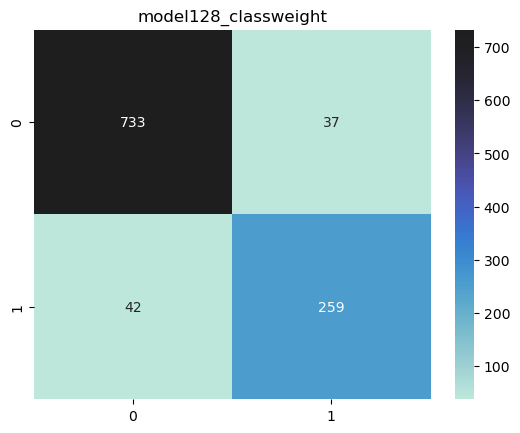

In [6]:
filtered_data, TP, FP, TN, FN, f1 = test_model(model, test_ds)
print(f'f1-score: {f1}')

array = [[TN, FP],
        [FN, TP]]

df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(df_cm, annot=True, center=TN, fmt='g')
plt.title('model128_classweight')

# plt.savefig('./documentation/model128_classweight.png')
plt.show()

In [7]:
model.save('./trained_models/model128_test')

INFO:tensorflow:Assets written to: ./trained_models/model128_test\assets


INFO:tensorflow:Assets written to: ./trained_models/model128_test\assets


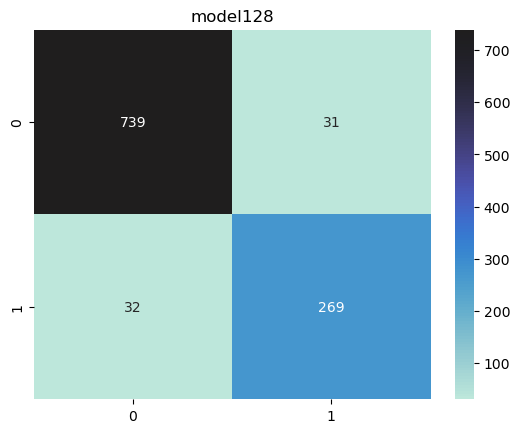

In [8]:
model128 = keras.models.load_model('./trained_models/model128')
# model128.save('./trained_models/model128_2')
filtered_data, TP, FP, TN, FN, f1 = test_model(model128, test_ds)
print(f'f1-score: {f1}')

array = [[TN, FP],
        [FN, TP]]

df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(df_cm, annot=True, center=TN, fmt='g')
plt.title('model128')

plt.show()